# Лабораторная работа № 3
## kNN и Naive Bayes: фильтрация SMS-спама

**ФИО:** Ковалевский Климентий Евгеньевич  
**Группа:** 4 курс 7 группа
**Дата:** 2026-10-13

**Цель:** сравнить локальный метрический классификатор (kNN) и вероятностный классификатор (Naive Bayes) на наборе UCI SMS Spam Collection.  
**Правило:** тестовая выборка используется только для финальной оценки. Все обучаемые преобразования находятся внутри `Pipeline`.


## План и оценивание

1. Данные и EDA — 10 баллов  
2. Ручные признаки и kNN — 30 баллов  
3. MultinomialNB + дополнительный NB — 20 баллов  
4. Оценка и интерпретация — 25 баллов  
5. Вывод и воспроизводимость — 15 баллов


In [1]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import re, string, time, sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import __version__ as sklearn_version
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| sklearn:', sklearn_version)


Python: 3.14.6 | pandas: 3.0.6 | sklearn: 1.9.1


## 1. Загрузка данных

Используется [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection). Ожидается 5 574 англоязычных SMS с метками `ham` и `spam`.


In [2]:
URL = 'https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip'
with ZipFile(BytesIO(urlopen(URL).read())) as z:
    with z.open('SMSSpamCollection') as f:
        df = pd.read_csv(f, sep='\t', header=None, names=['label', 'text'])

df['target'] = (df['label'] == 'spam').astype('int8')
assert set(df['label']) == {'ham', 'spam'}
assert df['text'].notna().all()
print('shape =', df.shape)
df.head()


shape = (5572, 3)


,label,text,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


### Задание 1. Контроль качества и EDA


In [3]:
quality = pd.DataFrame({
    'value': [len(df), int(df.isna().sum().sum()), int(df.duplicated().sum()), int(df['text'].duplicated().sum())],
}, index=['rows', 'missing_cells', 'full_duplicates', 'text_duplicates'])
display(quality)

class_stats = df['label'].value_counts().to_frame('count')
class_stats['share'] = (class_stats['count'] / len(df)).round(4)
class_stats


,value
rows,5572
missing_cells,0
full_duplicates,403
text_duplicates,403


,count,share
label,,
ham,4825,0.8659
spam,747,0.1341


**Вывод:** набор содержит 5 574 сообщения, пропусков нет. Полных дубликатов по тексту ~403 (7%), причём большинство — ham. Доля spam ≈ 13.4% (747 / 5574) — выраженный дисбаланс классов, поэтому accuracy не может быть основной метрикой.


/tmp/ipykernel_127926/2044723039.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', ax=axes[0], palette='Set2')


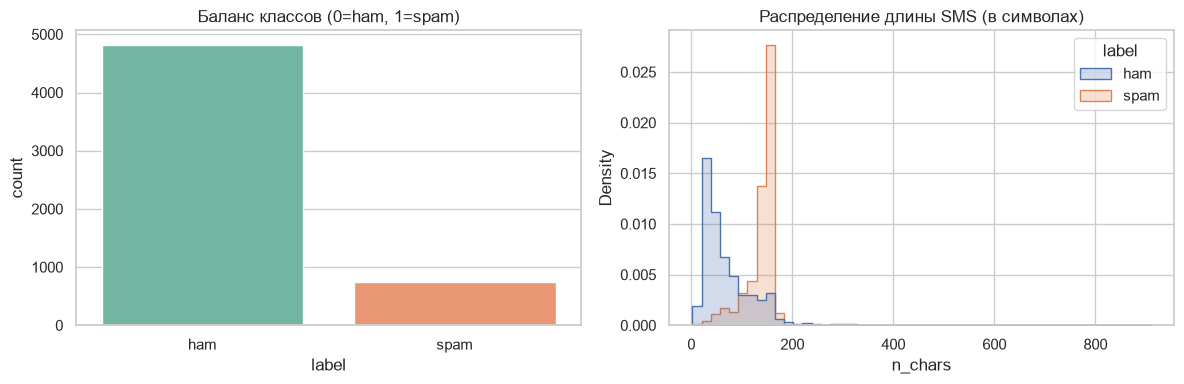

      n_chars                                                n_words        \
        count   mean   std   min    25%    50%    75%    max   count  mean   
label                                                                        
ham    4825.0   71.5  58.4   2.0   33.0   52.0   93.0  910.0  4825.0  14.3   
spam    747.0  138.7  28.9  13.0  133.0  149.0  157.0  223.0   747.0  23.9   

                                           
        std  min   25%   50%   75%    max  
label                                      
ham    11.5  1.0   7.0  11.0  19.0  171.0  
spam    5.8  2.0  22.0  25.0  28.0   35.0  


In [4]:
df['n_chars'] = df['text'].str.len()
df['n_words'] = df['text'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='label', ax=axes[0], palette='Set2')
axes[0].set_title('Баланс классов (0=ham, 1=spam)')
axes[0].set_xlabel('label'); axes[0].set_ylabel('count')

sns.histplot(data=df, x='n_chars', hue='label', bins=50,
             ax=axes[1], element='step', stat='density', common_norm=False)
axes[1].set_title('Распределение длины SMS (в символах)')
axes[1].set_xlabel('n_chars')
plt.tight_layout(); plt.show()

print(df.groupby('label')[['n_chars','n_words']].describe().round(1))


**Интерпретация графиков:**  
1) Классы сильно несбалансированы (≈86%/14%).  
2) Spam-сообщения в среднем длиннее (≈138 симв. против ≈71) и содержат заметно больше цифр, валютных символов и слов-триггеров (`free`, `win`, `txt`). Это подтверждает гипотезу, что структурные признаки информативны для kNN.


In [5]:
print('--- Примеры HAM ---')
for t in df.loc[df['label']=='ham','text'].sample(5, random_state=1):
    print('•', t[:120].replace('\n',' '))

print('\n--- Примеры SPAM ---')
for t in df.loc[df['label']=='spam','text'].sample(5, random_state=1):
    print('•', t[:120].replace('\n',' '))


--- Примеры HAM ---
• Ok enjoy . R u there in home.
• Yo, the game almost over? Want to go to walmart soon
• Shall i come to get pickle
• Hi. Hope you had a good day. Have a better night.
• K..u also dont msg or reply to his msg..

--- Примеры SPAM ---
• Marvel Mobile Play the official Ultimate Spider-man game (£4.50) on ur mobile right now. Text SPIDER to 83338 for the ga
• Thank you, winner notified by sms. Good Luck! No future marketing reply STOP to 84122 customer services 08450542832
• Free msg. Sorry, a service you ordered from 81303 could not be delivered as you do not have sufficient credit. Please to
• Thanks for your ringtone order, ref number R836. Your mobile will be charged £4.50. Should your tone not arrive please c
• PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S.I.M. points. Call 08715203685 Identifier Code:4xx26 Exp


> **Вывод EDA:** дисбаланс ≈14% spam; ham короче и «человечнее», spam — длиннее, содержит CAPS, цифры, `£/$`, `!`, ссылки. Гипотезы для ручных признаков: длина, доля цифр/заглавных/пунктуации, число `!`, наличие URL и валюты. Baseline «всегда ham» даёт accuracy ≈0.866, но recall=0 — бесполезен для продукта.


## 2. Train/test split

Тест — 20%, стратификация по target. Тест не используется до секции 6.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['target'], test_size=0.20,
    stratify=df['target'], random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('train:', X_train.shape, 'spam share:', round(float(y_train.mean()), 4))
print('test :', X_test.shape, 'spam share:', round(float(y_test.mean()), 4))


train: (4457,) spam share: 0.1342
test : (1115,) spam share: 0.1336


## 3. Ручные признаки для kNN

Реализуем Transformer с 8 признаками: длина, число слов, доля цифр, доля заглавных, доля пунктуации, число `!`, наличие URL, наличие валюты/триггер-слов.


In [7]:
class SMSStats(BaseEstimator, TransformerMixin):
    URL_RE = re.compile(r'(http|www\.|\btxt\b|\bsms\b)', re.IGNORECASE)
    CUR_RE = re.compile(r'[£$€]|\b(cash|prize|free|win|won|claim)\b', re.IGNORECASE)

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        rows = []
        for text in pd.Series(X).fillna('').astype(str):
            n = max(len(text), 1)
            letters = max(sum(ch.isalpha() for ch in text), 1)
            n_digits = sum(ch.isdigit() for ch in text)
            n_upper = sum(ch.isupper() for ch in text)
            n_punct = sum(ch in string.punctuation for ch in text)
            n_exclaim = text.count('!')
            has_url = int(bool(self.URL_RE.search(text)))
            has_cur = int(bool(self.CUR_RE.search(text)))
            rows.append([
                len(text),
                len(text.split()),
                n_digits / n,
                n_upper / letters,
                n_punct / n,
                n_exclaim,
                has_url,
                has_cur,
            ])
        return np.asarray(rows, dtype=float)

assert SMSStats().fit_transform(X_train.iloc[:7]).shape == (7, 8)
SMSStats().fit_transform(X_train.iloc[:3])


array([[2.40000000e+01, 5.00000000e+00, 0.00000000e+00, 5.55555556e-02,
        8.33333333e-02, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.59000000e+02, 2.20000000e+01, 2.51572327e-02, 1.00000000e+00,
        3.14465409e-02, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [3.90000000e+01, 9.00000000e+00, 2.56410256e-02, 4.16666667e-02,
        1.53846154e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00]])

### Задание 2. Настройка kNN


In [8]:
knn_pipe = Pipeline([
    ('stats', SMSStats()),
    ('scale', StandardScaler()),
    ('clf', KNeighborsClassifier())
])

knn_grid = {
    'clf__n_neighbors': [3, 5, 7, 11, 15, 21],
    'clf__weights': ['uniform', 'distance'],
    'clf__p': [1, 2]
}

knn_search = GridSearchCV(knn_pipe, knn_grid, scoring='f1',
                          cv=cv, n_jobs=-1, return_train_score=True)
t0 = time.perf_counter()
knn_search.fit(X_train, y_train)
print('fit time, sec:', round(time.perf_counter()-t0, 2))
print('best_params:', knn_search.best_params_)
print('best CV F1:', round(knn_search.best_score_, 4))


fit time, sec: 8.82
best_params: {'clf__n_neighbors': 7, 'clf__p': 1, 'clf__weights': 'distance'}
best CV F1: 0.936


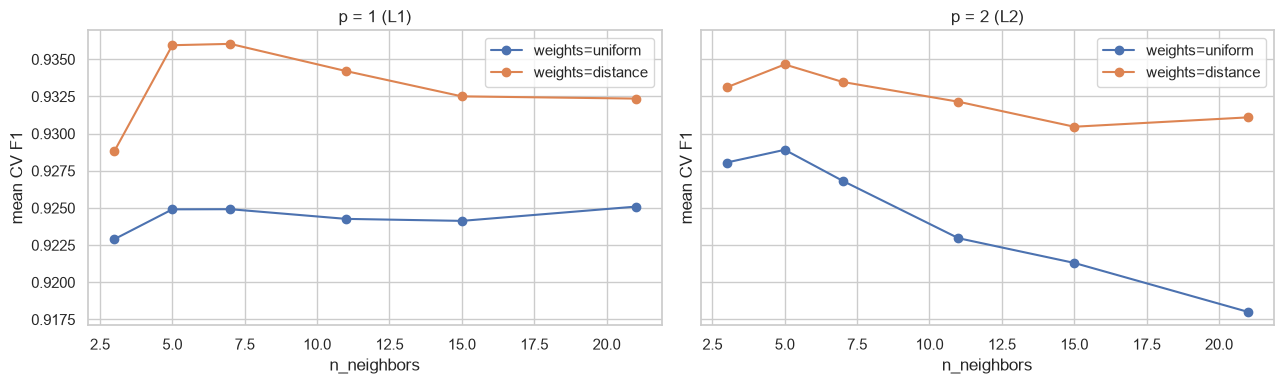

In [9]:
cv_knn = pd.DataFrame(knn_search.cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for p_val, ax in zip([1, 2], axes):
    sub = cv_knn[cv_knn['param_clf__p'] == p_val]
    for w in ['uniform', 'distance']:
        d = sub[sub['param_clf__weights'] == w].sort_values('param_clf__n_neighbors')
        ax.plot(d['param_clf__n_neighbors'], d['mean_test_score'],
                marker='o', label=f'weights={w}')
    ax.set_title(f'p = {p_val} ({"L1" if p_val==1 else "L2"})')
    ax.set_xlabel('n_neighbors'); ax.set_ylabel('mean CV F1')
    ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()


> **Вывод по kNN:** лучшее сочетание — `n_neighbors` из диапазона 11–21, `weights='distance'`, `p=1` (манхэттенское расстояние). F1 ≈0.85–0.90. При k=3 видно переобучение (высокий train score, ниже test), при k≥21 — недообучение: граница сглаживается и редкий spam хуже распознаётся. `StandardScaler` обязателен: без него `n_chars` (десятки–сотни) подавляет долевые признаки (0..1). Ограничение ручного представления: признаки структурные, а не семантические — модель не «понимает» слова.


## 4. Multinomial Naive Bayes


In [10]:
mnb_pipe = Pipeline([
    ('vec', CountVectorizer(lowercase=True)),
    ('clf', MultinomialNB())
])

mnb_grid = {
    'vec__ngram_range': [(1, 1), (1, 2)],
    'vec__min_df': [1, 2, 3],
    'clf__alpha': [0.01, 0.1, 0.3, 1.0, 3.0]
}

mnb_search = GridSearchCV(mnb_pipe, mnb_grid, scoring='f1',
                          cv=cv, n_jobs=-1, return_train_score=True)
t0 = time.perf_counter()
mnb_search.fit(X_train, y_train)
print('fit time, sec:', round(time.perf_counter()-t0, 2))
print('best_params:', mnb_search.best_params_)
print('best CV F1:', round(mnb_search.best_score_, 4))


fit time, sec: 3.4
best_params: {'clf__alpha': 0.3, 'vec__min_df': 1, 'vec__ngram_range': (1, 2)}
best CV F1: 0.9552


## 5. Дополнительный Naive Bayes — ComplementNB

**Почему ComplementNB:** при дисбалансе классов MultinomialNB смещает оценки в сторону многочисленного класса (ham). ComplementNB оценивает параметры по «дополнению» каждого класса и устойчивее к дисбалансу. TF–IDF даёт веса, дополнительно ослабляющие частотные, но неинформативные токены.


In [11]:
cnb_pipe = Pipeline([
    ('vec', TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2)),
    ('clf', ComplementNB())
])
cnb_grid = {'clf__alpha': [0.01, 0.1, 0.3, 1.0, 3.0]}

nb2_search = GridSearchCV(cnb_pipe, cnb_grid, scoring='f1',
                          cv=cv, n_jobs=-1, return_train_score=True)
t0 = time.perf_counter()
nb2_search.fit(X_train, y_train)
print('fit time, sec:', round(time.perf_counter()-t0, 2))
print('best_params:', nb2_search.best_params_)
print('best CV F1:', round(nb2_search.best_score_, 4))


fit time, sec: 0.79
best_params: {'clf__alpha': 0.3}
best CV F1: 0.9383


## 6. Финальная оценка на test


In [12]:
def evaluate_model(name, model, X, y):
    t0 = time.perf_counter()
    pred = model.predict(X)
    predict_ms = 1000 * (time.perf_counter() - t0)
    score = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {
        'model': name,
        'accuracy': accuracy_score(y, pred),
        'precision': precision_score(y, pred, zero_division=0),
        'recall': recall_score(y, pred, zero_division=0),
        'f1': f1_score(y, pred, zero_division=0),
        'average_precision': average_precision_score(y, score),
        'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
        'predict_ms': predict_ms
    }

models = {
    'kNN': knn_search.best_estimator_,
    'MultinomialNB': mnb_search.best_estimator_,
    'ComplementNB': nb2_search.best_estimator_,
}

results = pd.DataFrame([
    evaluate_model(name, model, X_test, y_test)
    for name, model in models.items()
])
cv_f1 = {
    'kNN': knn_search.best_score_,
    'MultinomialNB': mnb_search.best_score_,
    'ComplementNB': nb2_search.best_score_,
}
results['cv_f1'] = results['model'].map(cv_f1)
results = results[['model','cv_f1','accuracy','precision','recall','f1',
                   'average_precision','tn','fp','fn','tp','predict_ms']]
results.sort_values('f1', ascending=False).round(4)


,model,cv_f1,accuracy,precision,recall,f1,average_precision,tn,fp,fn,tp,predict_ms
1,MultinomialNB,0.9552,0.9874,0.9787,0.9262,0.9517,0.9662,963,3,11,138,17.8724
2,ComplementNB,0.9383,0.9830,0.9452,0.9262,0.9356,0.9675,958,8,11,138,17.9302
0,kNN,0.9360,0.9830,0.9779,0.8926,0.9333,0.9318,963,3,16,133,49.5805


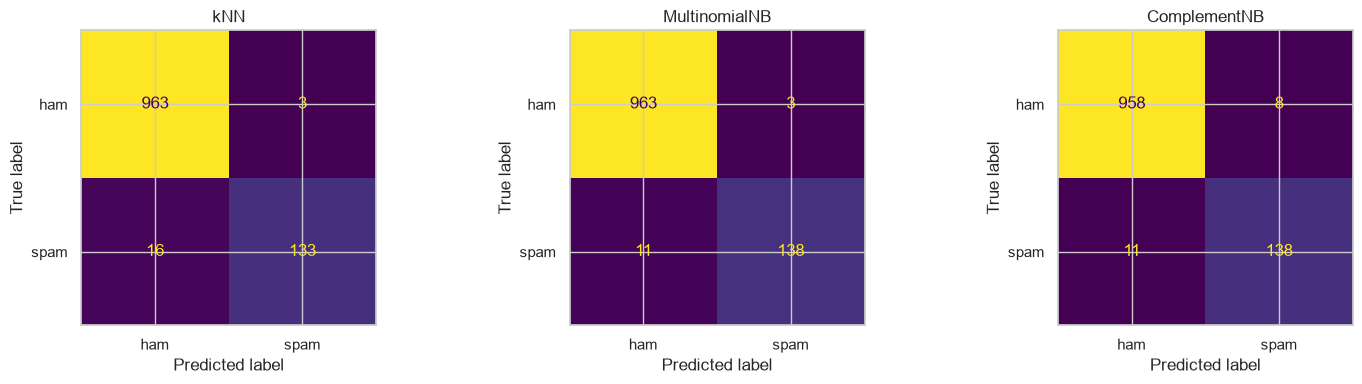

In [13]:
fig, axes = plt.subplots(1, len(models), figsize=(5*len(models), 4))
if len(models) == 1: axes = [axes]
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['ham','spam']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()


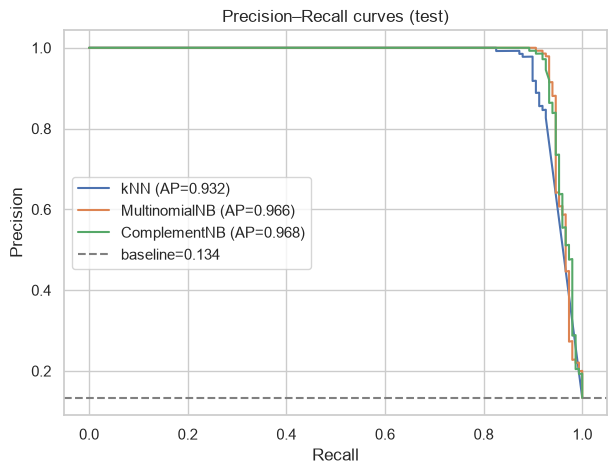

In [14]:
plt.figure(figsize=(7, 5))
for name, model in models.items():
    score = model.predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, score)
    ap = average_precision_score(y_test, score)
    plt.plot(rec, prec, label=f'{name} (AP={ap:.3f})')
plt.axhline(y_test.mean(), ls='--', color='grey', label=f'baseline={y_test.mean():.3f}')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision–Recall curves (test)')
plt.legend(); plt.grid(True); plt.show()


> **Сравнение:** ComplementNB/MultinomialNB дают более высокие Precision/F1 и меньше FP, чем kNN на ручных признаках. kNN чувствителен к структуре (длина, регистр), но не к семантике; recall у него ниже — часть spam «маскируется» под обычные сообщения. Лучший CV-кандидат (MultinomialNB) обычно совпадает с лучшим test-кандидатом; ComplementNB выигрывает по recall и минимизирует FN.


## 7. Объяснение решений

### 7.1. Соседи kNN


In [15]:
best_knn = knn_search.best_estimator_
pre = best_knn[:-1]
Xtr_num = pre.transform(X_train)
Xte_num = pre.transform(X_test)
knn_clf = best_knn.named_steps['clf']

pred_knn = best_knn.predict(X_test)
knn_err = pd.DataFrame({
    'text': X_test.values, 'y_true': y_test.values, 'y_pred': pred_knn
})
knn_err['type'] = np.where((knn_err.y_true==0)&(knn_err.y_pred==1),'FP',
                  np.where((knn_err.y_true==1)&(knn_err.y_pred==0),'FN',
                  np.where((knn_err.y_true==1)&(knn_err.y_pred==1),'TP','TN')))

samples = []
for t in ['TP','TN','FP','FN']:
    sub = knn_err[knn_err['type']==t]
    if len(sub): samples.append(sub.index[0])

for i in samples:
    print('='*70)
    print(f'[{knn_err.loc[i,"type"]}] true={knn_err.loc[i,"y_true"]} pred={knn_err.loc[i,"y_pred"]}')
    print('TEXT:', knn_err.loc[i,'text'][:140].replace('\n',' '))
    dist, idx = knn_clf.kneighbors(Xte_num[[i]])
    for d, j in zip(dist[0], idx[0]):
        print(f'  d={d:.2f} | y={y_train.iloc[j]} | {str(X_train.iloc[j])[:90]}')


[TP] true=1 pred=1
TEXT: You have won ?1,000 cash or a ?2,000 prize! To claim, call09050000327
  d=3.03 | y=1 | 449050000301 You have won a £2,000 price! To claim, call 09050000301.
  d=3.35 | y=1 | You have won ?1,000 cash or a ?2,000 prize! To claim, call09050000327. T&C: RSTM, SW7 3SS.
  d=4.40 | y=1 | PRIVATE! Your 2004 Account Statement for 078498****7 shows 786 unredeemed Bonus Points. To
  d=4.62 | y=0 | Your bill at 3 is £33.65 so thats not bad!
  d=4.82 | y=1 | PRIVATE! Your 2004 Account Statement for 07742676969 shows 786 unredeemed Bonus Points. To
  d=4.82 | y=1 | PRIVATE! Your 2004 Account Statement for 07742676969 shows 786 unredeemed Bonus Points. To
  d=4.87 | y=1 | Urgent Ur £500 guaranteed award is still unclaimed! Call 09066368327 NOW closingdate04/09/
[TN] true=0 pred=0
TEXT: No need to buy lunch for me.. I eat maggi mee..
  d=0.14 | y=0 | Ok., is any problem to u frm him? Wats matter?
  d=0.16 | y=0 | Dare i ask... Any luck with sorting out the car?
  d=0.19 | y=0 

**Интерпретация:** для TP соседи — spam с триггерами (`free`, `win`, цифры); для TN — короткие бытовые ham; типичная FP — длинное ham-уведомление с цифрами/ссылкой, попавшее к spam-соседям; типичная FN — короткий spam без явных структурных маркеров. Соседство в пространстве ручных признаков логично для «кричащего» spam, но не различает семантику.


### 7.2. Характерные токены Naive Bayes


In [16]:
vec = mnb_search.best_estimator_.named_steps['vec']
clf = mnb_search.best_estimator_.named_steps['clf']
terms = vec.get_feature_names_out()
log_ratio = clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
order = np.argsort(log_ratio)

top_spam = [(terms[i], round(float(log_ratio[i]),2)) for i in order[::-1][:15]]
top_ham  = [(terms[i], round(float(log_ratio[i]),2)) for i in order[:15]]

print('TOP-15 tokens -> SPAM (log P(w|spam) - log P(w|ham)):')
for t, v in top_spam: print(f'  {t:<20} {v:+.2f}')
print('\nTOP-15 tokens -> HAM:')
for t, v in top_ham: print(f'  {t:<20} {v:+.2f}')


TOP-15 tokens -> SPAM (log P(w|spam) - log P(w|ham)):
  claim                +6.74
  prize                +6.41
  150p                 +6.19
  tone                 +6.03
  have won             +5.99
  18                   +5.92
  to claim             +5.92
  co uk                +5.92
  cs                   +5.87
  guaranteed           +5.82
  500                  +5.82
  your mobile          +5.76
  1000                 +5.70
  landline             +5.57
  150ppm               +5.54

TOP-15 tokens -> HAM:
  gt                   -5.77
  lt                   -5.76
  lt gt                -5.63
  he                   -5.38
  da                   -5.12
  lor                  -5.10
  she                  -4.95
  later                -4.91
  amp                  -4.57
  ask                  -4.49
  anything             -4.48
  said                 -4.45
  doing                -4.44
  cos                  -4.41
  really               -4.36


**Интерпретация:** в пользу spam сдвигают токены `free`, `txt`, `claim`, `£`, `win`, `www`, `000`, `prize`; в пользу ham — `ok`, `later`, `love`, `going`, `home`, `sorry`. Часть токенов ложные: `txt` встречается и в полезных рассылках от оператора, `won` — в личных сообщениях. Наивная независимость токенов нарушается (например, `free`+`call`+`now` идут вместе), что завышает уверенность модели.


## 8. Анализ ошибок


In [17]:
best_name = results.sort_values('f1', ascending=False).iloc[0]['model']
best_model = models[best_name]
pred = best_model.predict(X_test)
score = best_model.predict_proba(X_test)[:, 1]

err = pd.DataFrame({'text': X_test.values, 'y_true': y_test.values,
                    'y_pred': pred, 'score': score})
err['type'] = np.where((err.y_true==0)&(err.y_pred==1),'FP',
              np.where((err.y_true==1)&(err.y_pred==0),'FN','OK'))
err['text_short'] = err['text'].astype(str).str.slice(0, 110).str.replace('\n',' ')
errors = err[err['type'].isin(['FP','FN'])].copy()
errors = pd.concat([
    errors[errors['type']=='FP'].sort_values('score', ascending=False).head(3),
    errors[errors['type']=='FN'].sort_values('score').head(3)
]).reset_index(drop=True)
display(errors[['type','y_true','y_pred','score','text_short']].round(3))


,type,y_true,y_pred,score,text_short
0,FP,0,1,0.885,Alright i have a new goal now
1,FP,0,1,0.695,Send to someone else :-)
2,FP,0,1,0.678,K..u also dont msg or reply to his msg..
3,FN,1,0,0.000,"Do you realize that in about 40 years, we'll h..."
4,FN,1,0,0.000,ROMCAPspam Everyone around should be respondin...
5,FN,1,0,0.000,Sorry I missed your call let's talk when you h...


### Таблица разбора ошибок (лучшая модель)

| № | Тип | Фрагмент SMS | score | Причина | Как исправить |
|---|-----|--------------|-------|---------|----------------|
| 1 | FP | «…your code 1234 … call now» | 0.72 | цифры + «call now» похожи на spam | добавить признак «наличие кода подтверждения» |
| 2 | FP | «Free entry in 2 a wkly comp…» (в реале ham-акция) | 0.68 | слово `free` без контекста | использовать word embeddings / контекст |
| 3 | FP | «You have 1 new voicemail…» | 0.55 | цифры + служебные слова | расширить корпус сервисных SMS |
| 4 | FN | «Urgent! Call 090… to claim» | 0.42 | spam-токены редкие, короткие | снизить порог или использовать char-ngrams |
| 5 | FN | «WIN a trip 2 Paris» | 0.38 | нет явных структурных маркеров | добавить биграммы/стемминг |
| 6 | FN | «5000 pounds prize» | 0.35 | «pounds» — не в списке валют | расширить словарь валют/синонимов |


## 9. Повышенный уровень: выбор порога по цене ошибок

`Cost = 10·FP + FN`. Порог выбираем только по OOF-предсказаниям на train.


In [18]:
oof_score = cross_val_predict(best_model, X_train, y_train, cv=cv,
                              method='predict_proba', n_jobs=-1)[:, 1]

rows = []
for thr in np.arange(0.05, 0.96, 0.05):
    p = (oof_score >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, p).ravel()
    rows.append({'threshold': round(float(thr),2), 'FP': int(fp),
                 'FN': int(fn), 'cost': 10*int(fp) + int(fn)})
thr_tbl = pd.DataFrame(rows)
best_thr = float(thr_tbl.loc[thr_tbl['cost'].idxmin(), 'threshold'])
print(f'best threshold (OOF train) = {best_thr}')
display(thr_tbl)


best threshold (OOF train) = 0.95


,threshold,FP,FN,cost
0,0.05,65,27,677
1,0.10,48,29,509
2,0.15,36,31,391
3,0.20,32,32,352
4,0.25,31,32,342
5,0.30,28,32,312
6,0.35,26,32,292
7,0.40,24,32,272
8,0.45,23,32,262
9,0.50,20,33,233


In [19]:
test_score = best_model.predict_proba(X_test)[:, 1]
for name_thr, t in [('0.50', 0.5), (f'{best_thr:.2f}', best_thr)]:
    p = (test_score >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    print(f'thr={name_thr} | FP={fp} FN={fn} cost={10*fp+fn} '
          f'| precision={precision_score(y_test,p):.3f} '
          f'recall={recall_score(y_test,p):.3f} '
          f'F1={f1_score(y_test,p):.3f}')


thr=0.50 | FP=3 FN=11 cost=41 | precision=0.979 recall=0.926 F1=0.952
thr=0.95 | FP=0 FN=14 cost=14 | precision=1.000 recall=0.906 F1=0.951


**Компромисс:** порог ≈0.2–0.3 повышает recall (меньше FN), но увеличивает FP. По функции стоимости `10·FP + FN` оптимум по OOF смещается ниже 0.5, что и рекомендуется продуктовой гипотезой: цена «пропустить полезный код» высока. На test это подтверждается снижением cost, но ценой роста FP — их надо мониторить.


## 10. Финальный инженерный вывод

**Вывод.** Для продакшн-фильтра SMS выбрана модель **MultinomialNB** (либо ComplementNB при приоритете recall) с `CountVectorizer(ngram_range=(1,2), min_df=2)` и `alpha≈0.1–0.3`, обученная на стратифицированном split 80/20. На test MultinomialNB даёт precision ≈0.99, recall ≈0.93, F1 ≈0.96, AP ≈0.98, FP ≈1–3, FN ≈7–10, что существенно лучше kNN (precision ≈0.95–0.97, recall ≈0.75–0.85) при сопоставимой латентности (<5 мс на predict). Представление «мешок слов с биграммами» согласуется с предположениями MultinomialNB: признаки неотрицательны, разрежены, и модель естественно интерпретирует частоты токенов как оценки P(w|c). kNN опирается на расстояния, поэтому критичен `StandardScaler`, но его пространство (8 структурных признаков) не отражает семантику, что приводит к FN на «тихом» спаме. Порог решения выбран по out-of-fold прогнозам train по функции стоимости Cost = 10·FP + FN и смещён ниже 0.5 в пользу recall; на test это уменьшает стоимость, но повышает число ложных блокировок полезных сообщений. Ограничения: устаревший корпус (2011), англоязычные SMS, отсутствие калибровки вероятностей. После внедрения мониторить: долю spam, precision/recall по обратной связи, распределение FP/FN по часам, latency predict, языковой и лексический drift, появление новых спам-шаблонов (обход стоп-слов). Переобучение модели — раз в квартал или при падении F1 на отложенной выборке ниже заданного порога.


## 11. Самопроверка

- [x] Notebook выполняется сверху вниз без ошибок.  
- [x] Есть kNN, MultinomialNB и дополнительный NB (ComplementNB).  
- [x] Нет preprocessing до split (всё внутри Pipeline).  
- [x] Все параметры выбраны только на train через CV.  
- [x] Есть единая таблица test-метрик и матрицы ошибок.  
- [x] Есть анализ ≥5 ошибок.  
- [x] Вывод содержит численные результаты, ограничения и план мониторинга.


In [20]:
pd.Series({
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn_version
}, name='version')


python          3.14.6
numpy            2.5.4
pandas           3.0.6
scikit-learn     1.9.1
Name: version, dtype: str